In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("DemandPulse is ready!")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

DemandPulse is ready!
Pandas: 2.2.3
Scikit-learn: 1.6.1


In [2]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("../data/raw")

train = pd.read_csv(DATA_DIR / "train.csv", low_memory=False)
store = pd.read_csv(DATA_DIR / "store.csv")

print("Training data:", train.shape)
print("Store data:", store.shape)

display(train.head())
display(store.head())

Training data: (1017209, 9)
Store data: (1115, 10)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [3]:
train.info()
store.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  object
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(2)
memory usage: 69.8+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   object 
 2   Assort

In [7]:
train.isnull().sum()

Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

In [8]:
print("Missing values in train:")
display(train.isnull().sum())

print("\nDuplicate rows:", train.duplicated().sum())

print("\nSales statistics:")
display(train["Sales"].describe())

print("\nNumber of unique stores:", train["Store"].nunique())

Missing values in train:


Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64


Duplicate rows: 0

Sales statistics:


count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64


Number of unique stores: 1115


In [12]:
train["Store"].value_counts()

Store
1      942
726    942
708    942
709    942
713    942
      ... 
159    758
637    758
636    758
633    758
155    758
Name: count, Length: 1115, dtype: int64

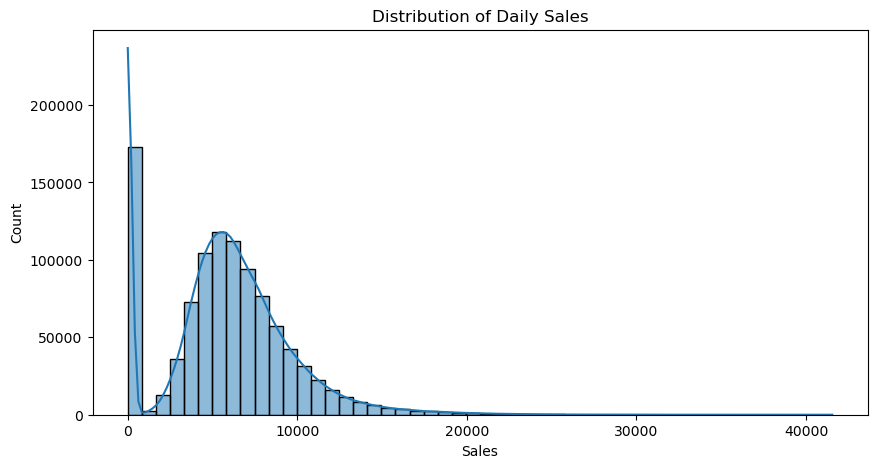

Mean sales: 5773.818972305593
Median sales: 5744.0
Minimum sales: 0
Maximum sales: 41551


In [13]:
plt.figure(figsize=(10, 5))
sns.histplot(train["Sales"], bins=50, kde=True)
plt.title("Distribution of Daily Sales")
plt.xlabel("Sales")
plt.show()

print("Mean sales:", train["Sales"].mean())
print("Median sales:", train["Sales"].median())
print("Minimum sales:", train["Sales"].min())
print("Maximum sales:", train["Sales"].max())

In [15]:
train["Sales"].skew()

np.float64(0.6414596158103787)

In [21]:
# Average sales by weekday, considering open stores only
open_df = train[train["Open"] == 1].copy()

weekday_sales = open_df.groupby("DayOfWeek")["Sales"].mean()
promo_sales = open_df.groupby("Promo")["Sales"].mean()

print("Average sales by weekday:")
display(weekday_sales)

print("\nAverage sales by promotion:")
display(promo_sales)

Average sales by weekday:


DayOfWeek
1    8216.073074
2    7088.113656
3    6728.122978
4    6767.310159
5    7072.677012
6    5874.840238
7    8224.723908
Name: Sales, dtype: float64


Average sales by promotion:


Promo
0    5929.407603
1    8228.281239
Name: Sales, dtype: float64